In [ ]:
import pandas as pd
from banco import conectar
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

NOME_BANCO = 'analise_de_gastos_publicos'

def consultar(sql):
    conexao = conectar(NOME_BANCO)
    if conexao is None:
        print("❌ Erro ao conectar")
        return None
    
    try:
        resultado = pd.read_sql(sql, conexao)
        conexao.close()
        return resultado
    except Exception as e:
        print(f"❌ Erro na query: {e}")
        conexao.close()
        return None

def reais(valor):
    if valor is None:
        return "R$ 0,00"
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

In [ ]:
print("=" * 60)
print("P1: RANKING DOS TOP 5 ÓRGÃOS SUPERIORES POR GASTO TOTAL")
print("=" * 60 + "\n")

sql_p1 = """
SELECT 
    nome_orgao_superior,
    ROUND(SUM(valor_diarias + valor_passagens + valor_outros_gastos), 2) AS gasto_total,
    COUNT(*) AS quantidade_viagens
FROM silver_2025_viagem
GROUP BY nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5
"""

df_p1 = consultar(sql_p1)

if df_p1 is not None and not df_p1.empty:
    df_p1['gasto_total_formatado'] = df_p1['gasto_total'].apply(reais)
    print(df_p1[['nome_orgao_superior', 'quantidade_viagens', 'gasto_total_formatado']].to_string(index=False))
    print("\n")
else:
    print("❌ Nenhum dado retornado.")

P1: RANKING DOS TOP 5 ÓRGÃOS SUPERIORES POR GASTO TOTAL

                           nome_orgao_superior  quantidade_viagens gasto_total_formatado
     Ministério da Justiça e Segurança Pública               75742     R$ 488.873.298,25
                          Ministério da Defesa               61912     R$ 156.565.001,54
                        Ministério da Educação               65295     R$ 111.905.403,15
Ministério do Meio Ambiente e Mudança do Clima               19413      R$ 50.123.043,80
              Ministério da Previdência Social                8190      R$ 40.669.392,58




In [ ]:
print("=" * 60)
print("P2: TOP 3 MEIOS DE TRANSPORTE MAIS UTILIZADOS")
print("=" * 60 + "\n")

sql_p2 = """
SELECT 
    meio_transporte,
    COUNT(*) AS quantidade_passagens,
    ROUND(SUM(valor_passagem), 2) AS faturamento_passagens
FROM silver_2025_passagem
WHERE meio_transporte IS NOT NULL AND meio_transporte <> ''
GROUP BY meio_transporte
ORDER BY quantidade_passagens DESC
LIMIT 3
"""

df_p2 = consultar(sql_p2)

if df_p2 is not None and not df_p2.empty:
    df_p2['faturamento_formatado'] = df_p2['faturamento_passagens'].apply(reais)
    print(df_p2[['meio_transporte', 'quantidade_passagens', 'faturamento_formatado']].to_string(index=False))
    print("\n")
else:
    print("❌ Nenhum dado retornado.")

P2: TOP 3 MEIOS DE TRANSPORTE MAIS UTILIZADOS

meio_transporte  quantidade_passagens faturamento_formatado
          Aéreo                164332     R$ 316.900.239,12
     Rodoviário                  2439         R$ 621.559,07
        Fluvial                   489         R$ 216.228,25




In [ ]:
print("=" * 60)
print("P3: VIAGEM COM O MAIOR GASTO TOTAL REGISTRADO")
print("=" * 60 + "\n")

sql_p3 = """
SELECT 
    identificador_processo_viagem,
    nome,
    cargo,
    nome_orgao_superior,
    (valor_diarias + valor_passagens + valor_outros_gastos) AS gasto_total
FROM silver_2025_viagem
ORDER BY gasto_total DESC
LIMIT 1
"""

df_p3 = consultar(sql_p3)

if df_p3 is not None and not df_p3.empty:
    viagem = df_p3.iloc[0]
    print(f"ID do Processo: {viagem['identificador_processo_viagem']}")
    print(f"Viajante: {viagem['nome']} ({viagem['cargo']})")
    print(f"Órgão: {viagem['nome_orgao_superior']}")
    print(f"Gasto Total: {reais(viagem['gasto_total'])}")
    print("\n")
else:
    print("❌ Nenhum dado retornado.")

P3: VIAGEM COM O MAIOR GASTO TOTAL REGISTRADO

ID do Processo: 0000000000020914280
Viajante: RENATO RODRIGUES DE AGUIAR FREIRE ()
Órgão: Ministério da Defesa
Gasto Total: R$ 260.696,46




In [ ]:
import pandas as pd
from sqlalchemy import text
from banco import conectar

print("=" * 60)
print("CRIANDO TABELA GOLD: RESUMO ORGÃO E TIPO DE PAGAMENTO")
print("=" * 60 + "\n")

sql_gold = """
DROP TABLE IF EXISTS gold_orgao_pagamento;

CREATE TABLE gold_orgao_pagamento AS
SELECT
    v.nome_orgao_superior,
    p.tipo_pagamento,
    COUNT(DISTINCT v.identificador_processo_viagem) AS quantidade_viagens,
    ROUND(SUM(p.valor), 2) AS valor_total_pago
FROM silver_2025_viagem v
JOIN silver_2025_pagamento p ON v.identificador_processo_viagem = p.identificador_processo_viagem
GROUP BY v.nome_orgao_superior, p.tipo_pagamento;
"""
def reais(valor):
    if valor is None or pd.isna(valor):
        return "R$ 0,00"
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')
conexao = conectar(NOME_BANCO)

if conexao is not None:
    with conexao.begin():
        conexao.execute(text(sql_gold))

    print("→ Tabela gold_orgao_pagamento criada e populada com sucesso!")

    df_teste = pd.read_sql(text("SELECT * FROM gold_orgao_pagamento LIMIT 10"), conexao)
    df_teste['valor_total_pago_formatado'] = df_teste['valor_total_pago'].apply(reais)
    print("\nPrimeiras linhas da tabela Gold:")
    print(df_teste[['nome_orgao_superior', 'tipo_pagamento', 'quantidade_viagens', 'valor_total_pago_formatado']].to_string(index=False))

    conexao.close()
    print("\n✅ Processo da Camada Gold concluído!")
else:
    print("❌ Falha na conexão com o banco de dados.")
print("=" * 60)

CRIANDO TABELA GOLD: RESUMO ORGÃO E TIPO DE PAGAMENTO

→ Tabela gold_orgao_pagamento criada e populada com sucesso!

Primeiras linhas da tabela Gold:
                                           nome_orgao_superior            tipo_pagamento  quantidade_viagens valor_total_pago_formatado
                                      Advocacia-Geral da União                   DIÁRIAS                1290            R$ 1.808.301,59
                                      Advocacia-Geral da União                  PASSAGEM                1003            R$ 2.337.440,24
                                      Advocacia-Geral da União               RESTITUIÇÃO                  30               R$ 10.444,20
                                      Advocacia-Geral da União Serviço correlato: seguro                  45               R$ 24.403,92
Banco Central do Brasil - Orçamento Fiscal e Seguridade Social                   DIÁRIAS                 335            R$ 1.180.152,91
Banco Central do Brasil - Orçament

In [ ]:
from banco import conectar, consultar
import pandas as pd

sql_contagem = """
SELECT 'raw_2025_viagem' AS tabela, COUNT(*) AS linhas FROM raw_2025_viagem
UNION ALL
SELECT 'raw_2025_passagem', COUNT(*) FROM raw_2025_passagem
UNION ALL
SELECT 'raw_2025_trecho', COUNT(*) FROM raw_2025_trecho
UNION ALL
SELECT 'raw_2025_pagamento', COUNT(*) FROM raw_2025_pagamento
UNION ALL
SELECT 'silver_2025_viagem', COUNT(*) FROM silver_2025_viagem
UNION ALL
SELECT 'silver_2025_passagem', COUNT(*) FROM silver_2025_passagem
UNION ALL
SELECT 'silver_2025_trecho', COUNT(*) FROM silver_2025_trecho
UNION ALL
SELECT 'silver_2025_pagamento', COUNT(*) FROM silver_2025_pagamento
UNION ALL
SELECT 'gold_orgao_pagamento', COUNT(*) FROM gold_orgao_pagamento
"""

conexao_local = conectar(NOME_BANCO)

if conexao_local is not None:
    try:
        df_contagem = pd.read_sql_query(sql_contagem, conexao_local)
        conexao_local.close()

        if not df_contagem.empty:
            print("=" * 60)
            print("CONTAGEM DE LINHAS POR TABELA (PIPELINE)")
            print("=" * 60)
            print(df_contagem.to_string(index=False))
        else:
            print("❌ Nenhum resultado encontrado.")
            
    except Exception as e:
        print(f"❌ Erro ao consultar: {e}")
        try:
            conexao_local.close()
        except:
            pass
else:
    print("❌ Não foi possível conectar ao banco de dados.")

CONTAGEM DE LINHAS POR TABELA (PIPELINE)
               tabela  linhas
 gold_orgao_pagamento     134
 silver_2025_passagem  167260
    raw_2025_passagem  167260
silver_2025_pagamento  606916
   silver_2025_viagem  341860
   silver_2025_trecho  763349
      raw_2025_viagem  341860
      raw_2025_trecho  763349
   raw_2025_pagamento  606916


In [ ]:
from banco import conectar, consultar
import pandas as pd

sql_nulls = """
SELECT 
    cpf_viajante,
    COUNT(*) AS quantidade
FROM silver_2025_viagem
WHERE cpf_viajante IS NULL OR cpf_viajante = '' OR cpf_viajante = '000.000.000-00'
GROUP BY cpf_viajante
"""

conexao_local = conectar(NOME_BANCO)

if conexao_local is not None:
    
    df_nulls = pd.read_sql(sql_nulls, conexao_local)
    conexao_local.close()
    
    if df_nulls is not None and not df_nulls.empty:
        print(f"Registros de viagens com CPF ausente/indefinido: {df_nulls['quantidade'].sum()}")
    else:
        print("✓ Nenhum registro com CPF ausente encontrado!")
else:
    print("❌ Falha na conexão com o banco de dados.")

Registros de viagens com CPF ausente/indefinido: 2566


In [ ]:
from banco import conectar
import pandas as pd

sql_datas = """
SELECT 
    MIN(periodo_data_inicio) AS primeira_viagem,
    MAX(periodo_data_fim) AS ultima_viagem
FROM silver_2025_viagem
"""

conexao_local = conectar(NOME_BANCO)

if conexao_local is not None:
    try:
        df_datas = pd.read_sql(sql_datas, conexao_local)
        conexao_local.close()

        if df_datas is not None and not df_datas.empty:
            print(df_datas.to_string(index=False))
        else:
            print("❌ Nenhum dado retornado ou erro na consulta.")
            
    except Exception as e:
        print(f"❌ Erro ao consultar: {e}")
        try:
            conexao_local.close()
        except:
            pass
else:
    print("❌ Falha na conexão com o banco de dados.")

primeira_viagem ultima_viagem
     2025-01-01    2026-04-05


In [ ]:
from banco import conectar
import pandas as pd

sql_ticket_medio = """
SELECT 
    cargo,
    COUNT(*) AS total_viagens,
    ROUND(AVG(valor_diarias), 2) AS media_diarias
FROM silver_2025_viagem
WHERE cargo IS NOT NULL AND cargo <> ''
GROUP BY cargo
ORDER BY media_diarias DESC
LIMIT 10
"""

def reais(valor):
    if valor is None or pd.isna(valor):
        return "R$ 0,00"
    return f"R$ {valor:,.2f}".replace(',', '_').replace('.', ',').replace('_', '.')

conexao_local = conectar(NOME_BANCO)

if conexao_local is not None:
    try:
        df_ticket = pd.read_sql(sql_ticket_medio, conexao_local)
        conexao_local.close()

        if df_ticket is not None and not df_ticket.empty:
            df_ticket['media_diarias_formatada'] = df_ticket['media_diarias'].apply(reais)
            
            print(df_ticket[['cargo', 'total_viagens', 'media_diarias_formatada']].to_string(index=False))
        else:
            print("❌ Nenhum dado retornado ou erro na consulta.")
            
    except Exception as e:
        print(f"❌ Erro ao consultar: {e}")
        try:
            conexao_local.close()
        except:
            pass
else:
    print("❌ Falha na conexão com o banco de dados.")

                                 cargo  total_viagens media_diarias_formatada
PAPILOSCOPISTA POLICIAL-SEGUNDA CLASSE              1           R$ 101.656,52
                     PRIMEIRO SARGENTO             89            R$ 59.729,41
                            SUBTENENTE             40            R$ 38.758,28
   AGENTE DE POLICIA - CLASSE ESPECIAL              3            R$ 32.019,30
                      SOLDADO 1 CLASSE              1            R$ 31.960,00
                       SEGUNDO TENENTE              9            R$ 27.078,02
                      SEGUNDO SARGENTO             78            R$ 22.411,46
         AUXILIAR DE SERVICOS DIVERSOS              5            R$ 18.472,59
             ARTIFICE DE MECANICA - NI              1            R$ 17.630,73
 DELEGADO DE POLICIA - CLASSE ESPECIAL              9            R$ 12.808,78


In [32]:
from banco import conectar
import pandas as pd

conexao_local = conectar(NOME_BANCO)

if conexao_local is not None:
    try:
        df_gold = pd.read_sql("SELECT * FROM gold_orgao_pagamento", conexao_local)
        conexao_local.close()

        if df_gold is not None and not df_gold.empty:
            df_gold.to_excel('relatorio_gastos_publicos_orgao.xlsx', index=False)
            print("✓ Arquivo 'relatorio_gastos_publicos_orgao.xlsx' criado com sucesso!")
        else:
            print("❌ A tabela gold_orgao_pagamento está vazia ou ocorreu um erro.")
            
    except Exception as e:
        print(f"❌ Erro ao consultar ou exportar: {e}")
        try:
            conexao_local.close()
        except:
            pass
else:
    print("❌ Falha na conexão com o banco de dados.")

✓ Arquivo 'relatorio_gastos_publicos_orgao.xlsx' criado com sucesso!


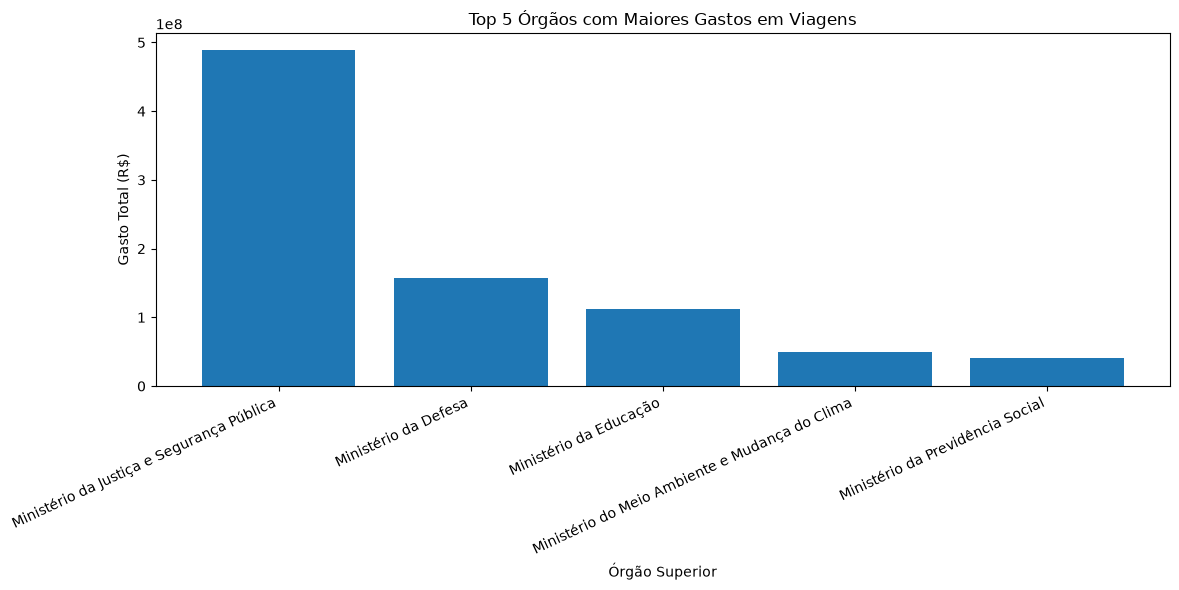

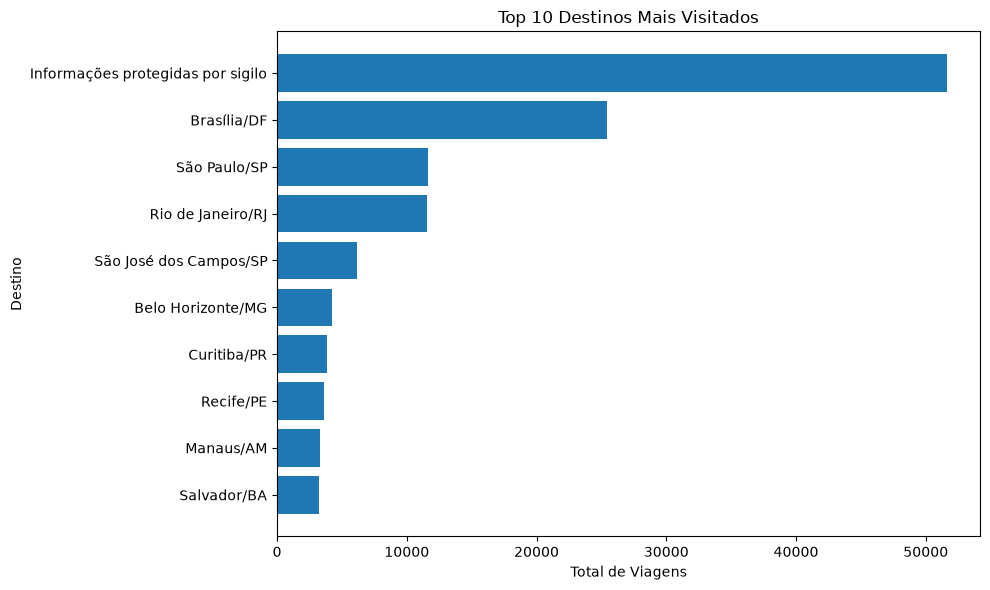

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
from banco import conectar

sql_graf = """
SELECT nome_orgao_superior, SUM(valor_diarias + valor_passagens + valor_outros_gastos) AS gasto_total
FROM silver_2025_viagem
GROUP BY nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5
"""

conexao_local = conectar(NOME_BANCO)

if conexao_local is not None:
    try:
        df_graf = pd.read_sql(sql_graf, conexao_local)
        conexao_local.close()

        if df_graf is not None and not df_graf.empty:
            plt.figure(figsize=(12, 6))
            plt.bar(df_graf['nome_orgao_superior'], df_graf['gasto_total'], color='#1f77b4')
            plt.xlabel('Órgão Superior')
            plt.ylabel('Gasto Total (R$)')
            plt.title('Top 5 Órgãos com Maiores Gastos em Viagens')
            plt.xticks(rotation=25, ha='right')
            plt.tight_layout()
            plt.show()
        else:
            print("❌ Nenhum dado retornado para gerar o gráfico.")
            
    except Exception as e:
        print(f"❌ Erro ao consultar: {e}")
        try:
            conexao_local.close()
        except:
            pass
else:
    print("❌ Falha na conexão com o banco de dados.")

    
sql_destinos = """
SELECT 
    destinos,
    COUNT(*) AS total_viagens
FROM silver_2025_viagem
WHERE destinos IS NOT NULL AND destinos <> ''
GROUP BY destinos
ORDER BY total_viagens DESC
LIMIT 10
"""

conexao_local = conectar(NOME_BANCO)
if conexao_local is not None:
    try:
        df_destinos = pd.read_sql(sql_destinos, conexao_local)
        conexao_local.close()

        if df_destinos is not None and not df_destinos.empty:
            plt.figure(figsize=(10, 6))
            plt.barh(df_destinos['destinos'], df_destinos['total_viagens'], color='#1f77b4')
            plt.xlabel('Total de Viagens')
            plt.ylabel('Destino')
            plt.title('Top 10 Destinos Mais Visitados')
            plt.gca().invert_yaxis()  # Deixa o destino com mais viagens no topo
            plt.tight_layout()
            plt.show()
        else:
            print("❌ Nenhum dado retornado para o gráfico de destinos.")
    except Exception as e:
        print(f"❌ Erro na consulta: {e}")
        try:
            conexao_local.close()
        except:
            pass

    

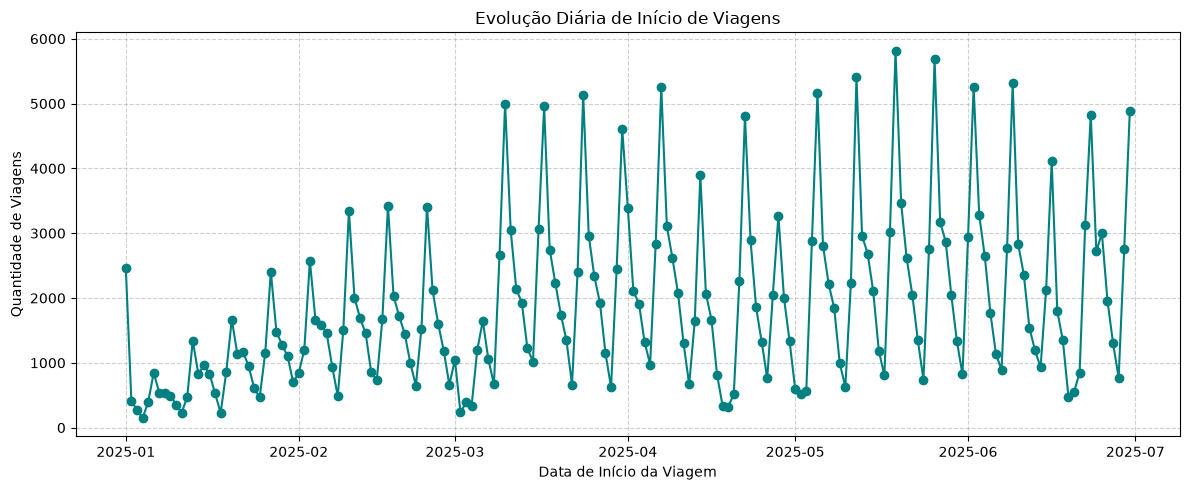

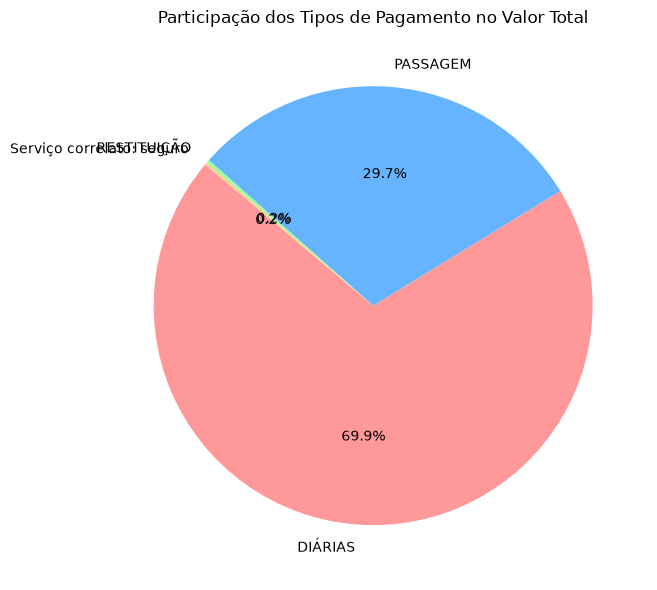

In [55]:
import matplotlib.pyplot as plt
import pandas as pd
from banco import conectar

sql_evolucao = """
SELECT 
    periodo_data_inicio,
    COUNT(*) AS total_viagens
FROM silver_2025_viagem
WHERE periodo_data_inicio IS NOT NULL
GROUP BY periodo_data_inicio
ORDER BY periodo_data_inicio ASC
"""

conexao_local = conectar(NOME_BANCO)
if conexao_local is not None:
    try:
        df_evolucao = pd.read_sql(sql_evolucao, conexao_local)
        conexao_local.close()

        if df_evolucao is not None and not df_evolucao.empty:
            df_evolucao['periodo_data_inicio'] = pd.to_datetime(df_evolucao['periodo_data_inicio'])
            
            plt.figure(figsize=(12, 5))
            plt.plot(df_evolucao['periodo_data_inicio'], df_evolucao['total_viagens'], marker='o', color='teal', linewidth=1.5)
            plt.xlabel('Data de Início da Viagem')
            plt.ylabel('Quantidade de Viagens')
            plt.title('Evolução Diária de Início de Viagens')
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"❌ Erro na consulta 1: {e}")
    try: conexao_local.close() 
    except: pass

sql_participacao = """
SELECT 
    tipo_pagamento,
    SUM(valor) AS valor_total
FROM silver_2025_pagamento
WHERE tipo_pagamento IS NOT NULL AND tipo_pagamento <> ''
GROUP BY tipo_pagamento
ORDER BY valor_total DESC
"""

conexao_local = conectar(NOME_BANCO)
if conexao_local is not None:
    try:
        df_part = pd.read_sql(sql_participacao, conexao_local)
        conexao_local.close()

        if df_part is not None and not df_part.empty:
            plt.figure(figsize=(8, 6))
            plt.pie(df_part['valor_total'], labels=df_part['tipo_pagamento'], autopct='%1.1f%%', 
                    startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
            plt.title('Participação dos Tipos de Pagamento no Valor Total')
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"❌ Erro na consulta 2: {e}")
        try: conexao_local.close() 
        except: pass



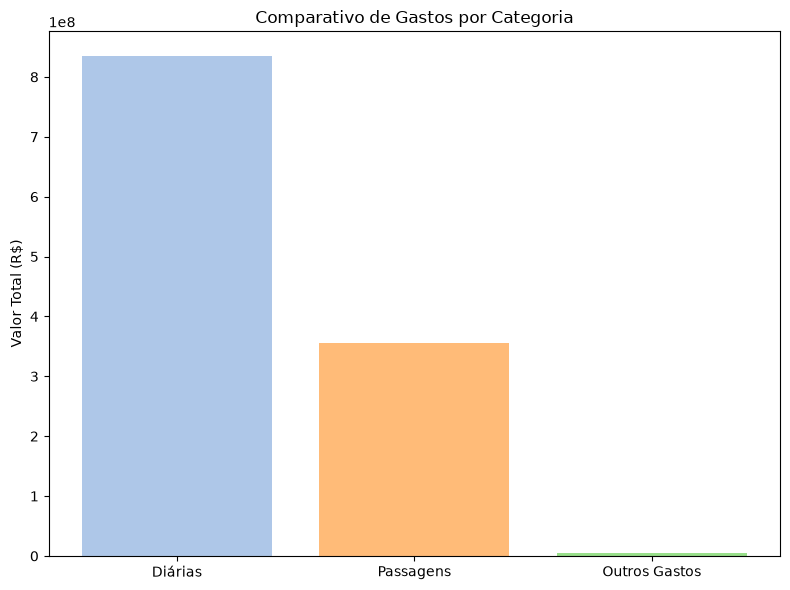

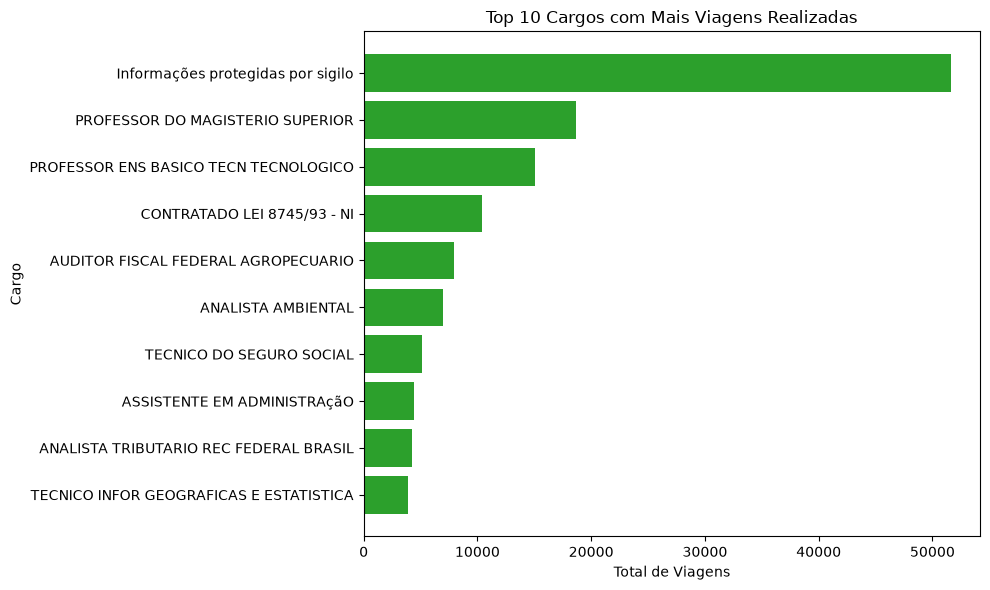

In [56]:
sql_categorias = """
SELECT 
    SUM(valor_diarias) AS total_diarias,
    SUM(valor_passagens) AS total_passagens,
    SUM(valor_outros_gastos) AS total_outros
FROM silver_2025_viagem
"""

conexao_local = conectar(NOME_BANCO)
if conexao_local is not None:
    try:
        df_cat = pd.read_sql(sql_categorias, conexao_local)
        conexao_local.close()

        if df_cat is not None and not df_cat.empty:
            # Transforma a linha única do DataFrame em listas para o gráfico
            categorias = ['Diárias', 'Passagens', 'Outros Gastos']
            valores = [df_cat['total_diarias'].values[0], 
                       df_cat['total_passagens'].values[0], 
                       df_cat['total_outros'].values[0]]

            plt.figure(figsize=(8, 6))
            plt.bar(categorias, valores, color=['#aec7e8', '#ffbb78', '#98df8a'])
            plt.ylabel('Valor Total (R$)')
            plt.title('Comparativo de Gastos por Categoria')
            plt.tight_layout()
            plt.show()
        else:
            print("❌ Nenhum dado retornado para o comparativo.")
    except Exception as e:
        print(f"❌ Erro na consulta: {e}")
        try:
            conexao_local.close()
        except:
            pass

        sql_top_cargos = """
SELECT 
    cargo,
    COUNT(*) AS total_viagens
FROM silver_2025_viagem
WHERE cargo IS NOT NULL AND cargo <> ''
GROUP BY cargo
ORDER BY total_viagens DESC
LIMIT 10
"""

conexao_local = conectar(NOME_BANCO)
if conexao_local is not None:
    try:
        df_cargos = pd.read_sql(sql_top_cargos, conexao_local)
        conexao_local.close()

        if df_cargos is not None and not df_cargos.empty:
            plt.figure(figsize=(10, 6))
            plt.barh(df_cargos['cargo'], df_cargos['total_viagens'], color='#2ca02c')
            plt.xlabel('Total de Viagens')
            plt.ylabel('Cargo')
            plt.title('Top 10 Cargos com Mais Viagens Realizadas')
            plt.gca().invert_yaxis() 
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"❌ Erro na consulta 3: {e}")
        try: conexao_local.close() 
        except: pass
        